# 📚 Hábitos dos estudantes e desempenho nas provas

Análise exploratória de dados com **pandas**, **matplotlib** e **seaborn**.

## Pergunta de negócio
> Quais hábitos dos estudantes (estudo, redes sociais, sono, exercício, saúde mental, alimentação) estão mais associados à nota final?

## Roteiro
1. Carregar e entender a base
2. Validar os dados
3. Quais hábitos mais se relacionam com a nota? (correlação)
4. Quem estuda mais tem melhor desempenho?
5. O tempo em redes sociais afeta a nota?
6. Alunos mais saudáveis vão melhor?
7. Há diferença entre gêneros?
8. Conclusões e limitações

> **Origem dos dados e crédito:** projeto prático desenvolvido a partir de vídeo do canal Eficiência Programada (detalhes no README). Os dados são **sintéticos**, ou seja, gerados artificialmente, então os resultados servem como exercício e não descrevem estudantes reais.

## 1. Importando e entendendo a base de dados

In [1]:
# Importação das bibliotecas necessárias
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
IMG = Path('images')
IMG.mkdir(exist_ok=True)

In [2]:
# Lendo o arquivo csv
df = pd.read_csv(r'dados/student_habits_performance.csv')

In [3]:
# Visualizando os dados
df.head()

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


### Dicionário de dados

| Coluna | Descrição |
|---|---|
| `student_id` | Identificador do estudante |
| `age`, `gender` | Idade e gênero |
| `study_hours_per_day` | Horas de estudo por dia |
| `social_media_hours` | Horas em redes sociais por dia |
| `netflix_hours` | Horas de streaming por dia |
| `part_time_job` | Tem emprego de meio período (Yes/No) |
| `attendance_percentage` | Percentual de presença nas aulas |
| `sleep_hours` | Horas de sono por dia |
| `diet_quality` | Qualidade da alimentação (Poor, Fair, Good) |
| `exercise_frequency` | Frequência de exercícios (0 a 6) |
| `parental_education_level` | Escolaridade dos pais |
| `internet_quality` | Qualidade da internet |
| `mental_health_rating` | Nota de saúde mental (1 a 10) |
| `extracurricular_participation` | Participa de atividades extracurriculares (Yes/No) |
| `exam_score` | **Nota final (variável analisada)** |

In [4]:
# Tipos de dados
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     1000 non-null   str    
 1   age                            1000 non-null   int64  
 2   gender                         1000 non-null   str    
 3   study_hours_per_day            1000 non-null   float64
 4   social_media_hours             1000 non-null   float64
 5   netflix_hours                  1000 non-null   float64
 6   part_time_job                  1000 non-null   str    
 7   attendance_percentage          1000 non-null   float64
 8   sleep_hours                    1000 non-null   float64
 9   diet_quality                   1000 non-null   str    
 10  exercise_frequency             1000 non-null   int64  
 11  parental_education_level       909 non-null    str    
 12  internet_quality               1000 non-null   str    
 13  

## 2. Validação dos dados

In [5]:
nulos = df.isna().sum()
display(nulos[nulos > 0].to_frame('nulos'))

print('Linhas duplicadas:', df.duplicated().sum())
print('IDs duplicados:', df['student_id'].duplicated().sum())
print('Alunos com nota no teto (100):', (df['exam_score'] >= 100).sum())

df.describe().T

,nulos
parental_education_level,91


Linhas duplicadas: 0
IDs duplicados: 0
Alunos com nota no teto (100): 48


,count,mean,std,min,25%,50%,75%,max
age,1000.0,20.4980,2.308100,17.0,18.750,20.0,23.000,24.0
study_hours_per_day,1000.0,3.5501,1.468890,0.0,2.600,3.5,4.500,8.3
social_media_hours,1000.0,2.5055,1.172422,0.0,1.700,2.5,3.300,7.2
netflix_hours,1000.0,1.8197,1.075118,0.0,1.000,1.8,2.525,5.4
attendance_percentage,1000.0,84.1317,9.399246,56.0,78.000,84.4,91.025,100.0
sleep_hours,1000.0,6.4701,1.226377,3.2,5.600,6.5,7.300,10.0
exercise_frequency,1000.0,3.0420,2.025423,0.0,1.000,3.0,5.000,6.0
mental_health_rating,1000.0,5.4380,2.847501,1.0,3.000,5.0,8.000,10.0
exam_score,1000.0,69.6015,16.888564,18.4,58.475,70.5,81.325,100.0


**Leitura:** não há linhas nem IDs duplicados. A única coluna com valores nulos é `parental_education_level` (**91 registros, 9,1%**), que não é usada nesta análise. Há **48 alunos (4,8%) com nota 100**, o que indica um teto na escala: notas altas não podem passar de 100, e isso limita as médias dos grupos que mais se saem bem.

## 3. Quais hábitos impactam mais o desempenho dos alunos?

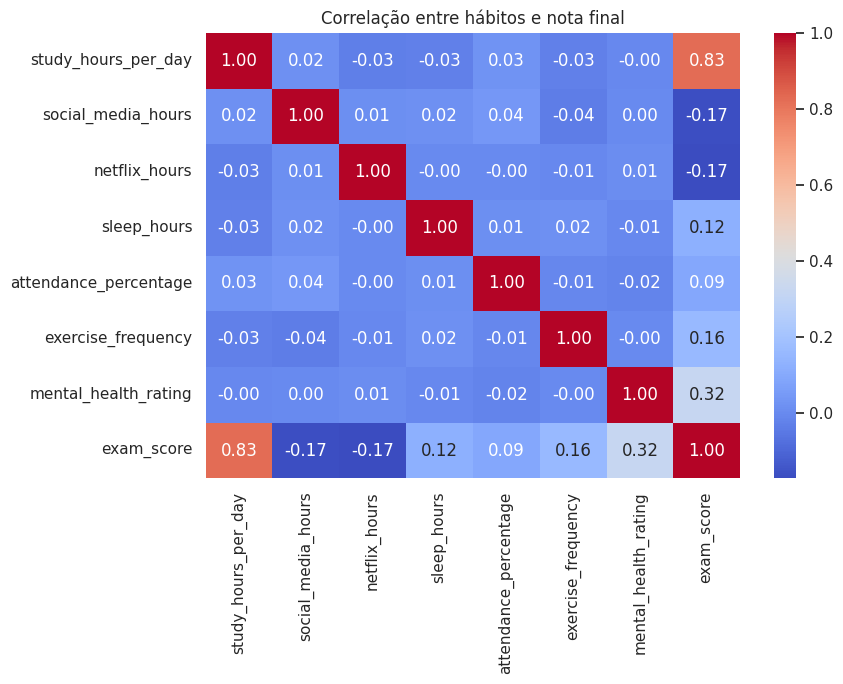

In [6]:
# Colunas numéricas
cols = [
    "study_hours_per_day",
    "social_media_hours",
    "netflix_hours",
    "sleep_hours",
    "attendance_percentage",
    "exercise_frequency",
    "mental_health_rating",
    "exam_score",
]

# Plotar mapa de calor (heatmap) para visualizar a correlação entre as colunas numéricas
plt.figure(figsize=(9, 7))
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlação entre hábitos e nota final")
plt.tight_layout()
plt.savefig(IMG / '01_correlacao_habitos.png', dpi=150)
plt.show()

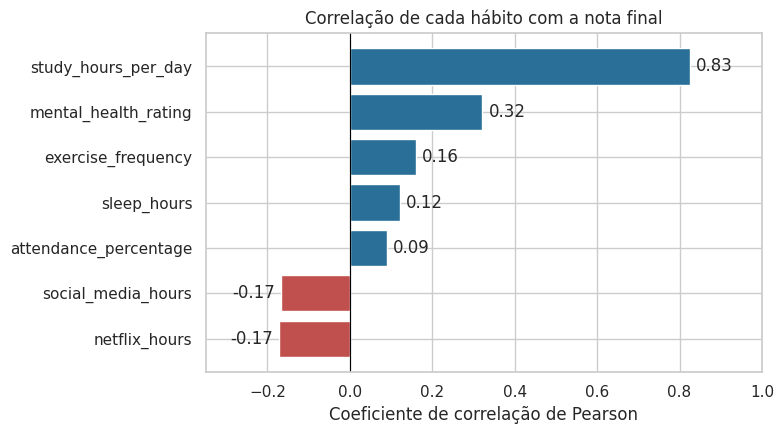

In [7]:
# Ranking: correlação de cada hábito com a nota final
ranking = df[cols].corr()['exam_score'].drop('exam_score').sort_values()

plt.figure(figsize=(8, 4.5))
cores = ['#c0504d' if v < 0 else '#2a6f97' for v in ranking.values]
plt.barh(ranking.index, ranking.values, color=cores)
for i, v in enumerate(ranking.values):
    plt.text(v + (0.015 if v >= 0 else -0.015), i, f'{v:.2f}', va='center', ha='left' if v >= 0 else 'right')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlim(-0.35, 1.0)
plt.title('Correlação de cada hábito com a nota final')
plt.xlabel('Coeficiente de correlação de Pearson')
plt.tight_layout()
plt.savefig(IMG / '02_ranking_correlacao.png', dpi=150)
plt.show()

**Leitura:** as **horas de estudo** são, de longe, o hábito mais associado à nota (correlação de **0,83**). Depois vêm a nota de saúde mental (0,32), a frequência de exercícios (0,16), as horas de sono (0,12) e a presença (0,09). Streaming (-0,17) e redes sociais (-0,17) têm correlação negativa e fraca.

> Correlação mede associação, **não causa**. Um coeficiente alto não prova que um hábito provoca a nota.

## 4. Alunos que mais estudam têm melhor desempenho?

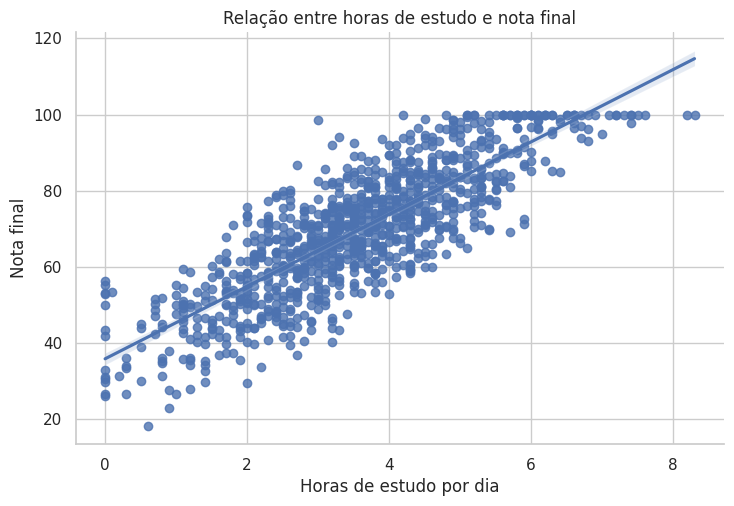

In [8]:
# Gráfico de dispersão com linha de regressão para exam_score vs study_hours_per_day
# x = "study_hours_per_day" / y = "exam_score"
sns.lmplot(data=df, x="study_hours_per_day", y="exam_score", aspect=1.5)
plt.title("Relação entre horas de estudo e nota final")
plt.xlabel("Horas de estudo por dia")
plt.ylabel("Nota final")
plt.savefig(IMG / '03_estudo_vs_nota.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# Comparando médias: quem estuda >5h x <2h
filtro_estudo_alto = df["study_hours_per_day"] > 5
filtro_estudo_baixo = df["study_hours_per_day"] < 2

grupo_estudo_alto = df[filtro_estudo_alto]["exam_score"]
grupo_estudo_baixo = df[filtro_estudo_baixo]["exam_score"]

print("Média de nota final para quem estuda mais de 5h/dia:", grupo_estudo_alto.mean())
print("Média de nota final para quem estuda menos de 2h/dia:", grupo_estudo_baixo.mean())
print("Alunos em cada grupo:", len(grupo_estudo_alto), "e", len(grupo_estudo_baixo))

Média de nota final para quem estuda mais de 5h/dia: 90.79419354838709
Média de nota final para quem estuda menos de 2h/dia: 45.56390977443609
Alunos em cada grupo: 155 e 133


**Leitura:** a relação é praticamente linear: cada hora a mais de estudo vem acompanhada de nota maior. Quem estuda mais de 5h por dia (155 alunos) tem média de **90,8**, contra **45,6** de quem estuda menos de 2h (133 alunos), uma diferença de cerca de **45,2 pontos**. Como há alunos no teto de 100, a média do grupo que mais estuda fica levemente subestimada.

## 5. O tempo gasto em redes sociais afeta o desempenho dos alunos?

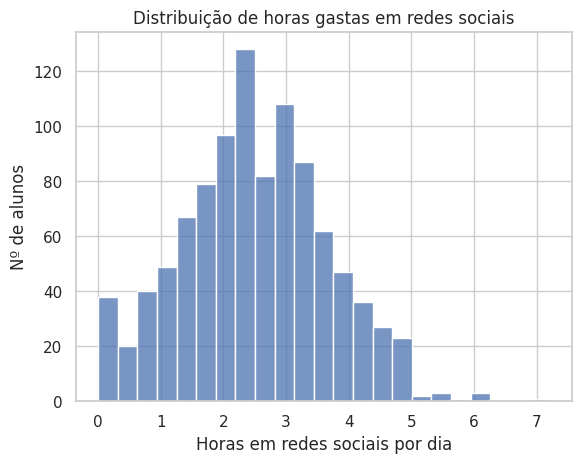

In [10]:
# Redes sociais: distribuição geral (Histograma)
# x = "social_media_hours"
sns.histplot(data=df, x="social_media_hours")
plt.title("Distribuição de horas gastas em redes sociais")
plt.xlabel("Horas em redes sociais por dia")
plt.ylabel("Nº de alunos")
plt.savefig(IMG / '04_distribuicao_redes_sociais.png', dpi=150, bbox_inches='tight')
plt.show()

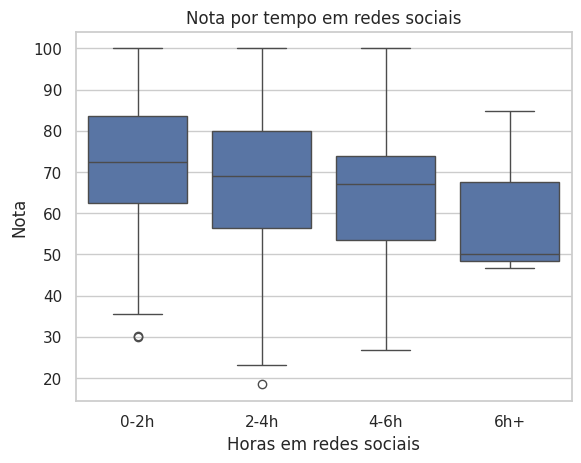

In [11]:
# Avaliando notas médias
# por diferentes intervalos (bins) de períodos gastos em redes sociais
# ["0-2h", "2-4h", "4-6h", "6h+"]
df["social_media_bin"] = pd.cut(
    df["social_media_hours"],
    bins=[0, 2, 4, 6, float("inf")],
    labels=["0-2h", "2-4h", "4-6h", "6h+"],
    include_lowest=True,
)

sns.boxplot(data=df, x="social_media_bin", y="exam_score",)
plt.title("Nota por tempo em redes sociais")
plt.xlabel("Horas em redes sociais")
plt.ylabel("Nota")
plt.savefig(IMG / '05_nota_por_redes_sociais.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# Quantos alunos há em cada faixa e qual a média de nota
df.groupby("social_media_bin", observed=True)["exam_score"].agg(alunos="count", media="mean").round(1)

,alunos,media
social_media_bin,,
0-2h,355,72.8
2-4h,549,68.4
4-6h,93,65.0
6h+,3,60.6


**Leitura:** quanto mais tempo em redes sociais, menor a nota média: de **72,8** (0-2h) para **65,0** (4-6h). Atenção à faixa **6h+, que tem apenas 3 alunos**, número pequeno demais para tirar conclusão. Como a maioria dos alunos fica entre 0 e 4 horas, a comparação mais confiável é entre as três primeiras faixas.

## 6. Alunos mais saudáveis têm melhores desempenhos?

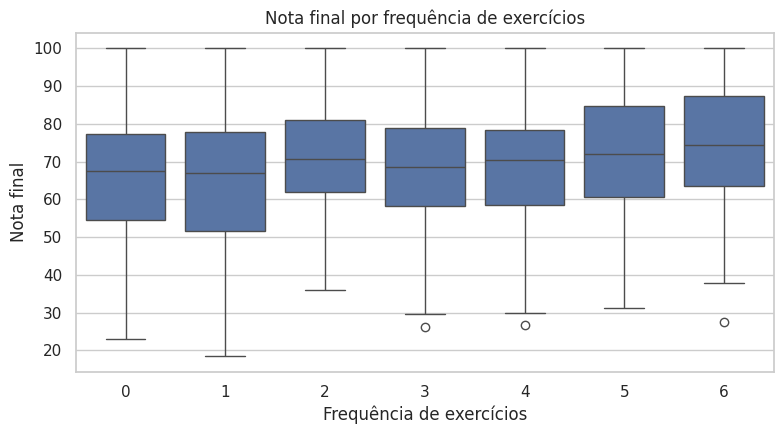

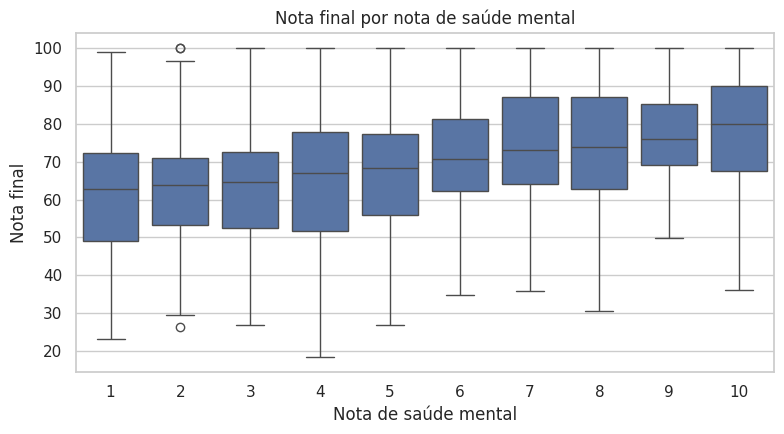

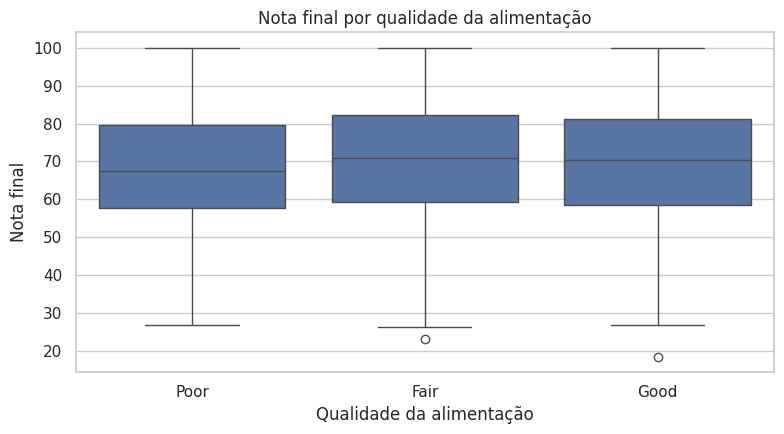

In [13]:
# Frequência de exercícios físicos, saúde mental e qualidade da alimentação
rotulos = {
    "exercise_frequency": ("Frequência de exercícios", "06_nota_por_exercicio.png"),
    "mental_health_rating": ("Nota de saúde mental", "07_nota_por_saude_mental.png"),
    "diet_quality": ("Qualidade da alimentação", "08_nota_por_alimentacao.png"),
}

for col, (titulo, arquivo) in rotulos.items():
    ordem = ["Poor", "Fair", "Good"] if col == "diet_quality" else None
    plt.figure(figsize=(8, 4.5))
    sns.boxplot(x=col, y="exam_score", data=df, order=ordem)
    plt.title(f"Nota final por {titulo.lower()}")
    plt.xlabel(titulo)
    plt.ylabel("Nota final")
    plt.tight_layout()
    plt.savefig(IMG / arquivo, dpi=150)
    plt.show()

In [14]:
# Médias de nota por grupo
for col in ["exercise_frequency", "mental_health_rating", "diet_quality"]:
    display(df.groupby(col)["exam_score"].agg(alunos="count", media="mean").round(1))

,alunos,media
exercise_frequency,,
0,144,66.4
1,146,65.8
2,122,70.5
3,153,68.4
4,134,68.7
5,149,72.7
6,152,74.6


,alunos,media
mental_health_rating,,
1,102,62.4
2,94,63.4
3,105,64.5
4,110,65.7
5,99,66.8
6,108,71.1
7,91,74.3
8,105,74.6
9,87,76.9


,alunos,media
diet_quality,,
Fair,437,70.4
Good,378,69.4
Poor,185,68.1


**Leitura:**
- **Saúde mental:** a nota média sobe de **62,4** (nota 1) para **78,0** (nota 10), um aumento consistente de cerca de 15,6 pontos.
- **Exercícios:** média de **66,4** para quem não se exercita e **74,6** para quem se exercita no nível máximo (6), com alguma oscilação no meio.
- **Alimentação:** quase sem efeito. As médias são **68,1** (Poor), **70,4** (Fair) e **69,4** (Good), e a ordem nem é crescente: "Fair" supera "Good".

## 7. Há diferença nas notas entre mulheres e homens?

In [15]:
# Estatística por gênero (média e desvio padrão)
df.groupby(["gender"])["exam_score"].agg(["mean", "std"])

,mean,std
gender,,
Female,69.741372,16.899351
Male,69.368344,17.150875
Other,70.647619,13.755890


In [16]:
# Avaliar distribuição de gênero
df["gender"].value_counts(normalize=True)

gender
Female    0.481
Male      0.477
Other     0.042
Name: proportion, dtype: float64

**Leitura:** praticamente não há diferença: média de **69,7** (feminino), **69,4** (masculino) e **70,6** (outro). O grupo "Other" tem só **42 alunos (4,2%)**, então sua média é menos confiável.

## 8. Conclusões

> **Aviso:** os dados são sintéticos, então estas conclusões ilustram a técnica de análise e não o comportamento de estudantes reais.

1. **Estudo é o hábito mais associado à nota** (correlação de 0,83); quem estuda mais de 5h por dia tem média cerca de 45,2 pontos maior que quem estuda menos de 2h.
2. **Saúde mental e exercícios** vêm em seguida, com associação positiva moderada a fraca.
3. **Redes sociais e streaming** têm associação negativa fraca com a nota.
4. **Alimentação e gênero** mostram diferenças desprezíveis.

## 9. Limitações e próximos passos

**Limitações**
- Os dados são sintéticos: as relações refletem como foram gerados, não o mundo real.
- Correlação não é causalidade. Por exemplo, alunos mais motivados podem estudar mais *e* ter notas maiores.
- Os hábitos se influenciam entre si (quem estuda mais pode usar menos redes sociais), e a análise olha um hábito por vez.
- Há um teto em 100 (alguns alunos), e os grupos "6h+ em redes sociais" e "Other" são muito pequenos.

**Próximos passos**
- Usar uma regressão linear múltipla para medir o efeito de cada hábito com os demais controlados.
- Testar a significância estatística das diferenças entre grupos.
- Repetir a análise com dados reais de alguma instituição, mantendo as questões de privacidade.